# DS201 · LAB 4: ENCODER–DECODER VÀ ATTENTION CHO DỊCH MÁY

Bài tập Phần C, dịch máy Anh–Việt. Ba mô hình dùng chung dữ liệu, từ điển, cấu hình huấn luyện và cách giải mã, chỉ khác phần decoder:

- Bài 1: encoder–decoder LSTM không attention
- Bài 2: decoder có Bahdanau attention (additive)
- Bài 3: decoder có Luong attention (global, general score, input feeding)

Notebook chạy trên Kaggle GPU. Dữ liệu là small-PhoMT theo link trong đề.

## 1. Thư viện và cấu hình

In [1]:
# Kaggle chưa cài sẵn rouge-score và sacrebleu
%pip install -q --disable-pip-version-check rouge-score sacrebleu

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib, json, random, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer, tokenizers
from sacrebleu.metrics import BLEU

In [3]:
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_all()
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
gpu = torch.cuda.get_device_name(0) if device.type == 'cuda' else '-'
print('torch', torch.__version__, '| device:', device, '| GPU:', gpu)

torch 2.11.0+cu130 | device: cuda | GPU: Tesla T4


Cấu hình chung theo đề: 3 lớp LSTM mỗi bên, hidden 256, embedding 256, dropout 0.3, Adam lr 1e-3, batch 32, tối đa 10 epoch, câu dài tối đa 50 từ, dùng toàn bộ train/dev/test.

In [4]:
cfg = dict(
    emb=256, hidden=256, layers=3, dropout=0.3,
    batch=32, lr=1e-3, teacher_ratio=0.5, clip=1.0,
    epochs=10, max_words=50, vocab_limit=10000, min_freq=2,
    train_limit=None, dev_limit=None,
)
for k, v in cfg.items():
    print(f'{k:14}{v}')

emb           256
hidden        256
layers        3
dropout       0.3
batch         32
lr            0.001
teacher_ratio 0.5
clip          1.0
epochs        10
max_words     50
vocab_limit   10000
min_freq      2
train_limit   None
dev_limit     None


In [5]:
WORK = Path.cwd()
DATA = WORK/'data'
ART = WORK/'artifacts'
ART.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3

## 2. Dữ liệu small-PhoMT

Nếu notebook có dataset chứa ba file trong `/kaggle/input` thì đọc từ đó, không thì tải từ Google Drive (cần bật Internet). File nào cũng phải khớp SHA-256 trước khi dùng.

In [6]:
DATA_FILES = [
    dict(file='small-train.json',
         url='https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
         sha256='f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'),
    dict(file='small-dev.json',
         url='https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
         sha256='fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'),
    dict(file='small-test.json',
         url='https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
         sha256='1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'),
]

def sha256(content):
    return hashlib.sha256(content).hexdigest()

def locate(item):
    kaggle_input = Path('/kaggle/input')
    found = sorted(kaggle_input.rglob(item['file'])) if kaggle_input.is_dir() else []
    path = found[0] if found else DATA/item['file']
    if not path.exists():
        with urllib.request.urlopen(item['url'], timeout=120) as r:
            content = r.read()
        if sha256(content) != item['sha256']:
            raise ValueError('Tải về sai nội dung: ' + item['file'])
        DATA.mkdir(parents=True, exist_ok=True)
        path.write_bytes(content)
    if sha256(path.read_bytes()) != item['sha256']:
        raise ValueError('Sai SHA-256: ' + item['file'])
    return path

paths = {item['file']: locate(item) for item in DATA_FILES}
for name, path in paths.items():
    print(name, '->', path)

small-train.json -> /kaggle/input/datasets/ngmaidnghi/dataaaa/data/small-train.json
small-dev.json -> /kaggle/input/datasets/ngmaidnghi/dataaaa/data/small-dev.json
small-test.json -> /kaggle/input/datasets/ngmaidnghi/dataaaa/data/small-test.json


Tiền xử lý: bỏ BOM, chuẩn hóa NFC, viết thường, tách theo khoảng trắng. Chỉ giữ cặp có cả hai phía dài từ 1 đến 50 token, không cắt câu.

In [7]:
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    raw[split] = json.loads(paths[f'small-{split}.json'].read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        src, tgt = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(src) <= cfg['max_words'] and 1 <= len(tgt) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=src, tgt=tgt))
    kept = filtered[split]
    print(f"{split:5} gốc {len(raw[split]):5} | sau lọc {len(kept):5} | "
          f"độ dài TB EN {np.mean([len(r['src']) for r in kept]):.1f}, "
          f"VI {np.mean([len(r['tgt']) for r in kept]):.1f}")

assert [len(raw[s]) for s in ['train', 'dev', 'test']] == [20000, 2000, 2000]

train gốc 20000 | sau lọc 18607 | độ dài TB EN 17.3, VI 20.6
dev   gốc  2000 | sau lọc  1901 | độ dài TB EN 18.6, VI 23.2
test  gốc  2000 | sau lọc  1786 | độ dài TB EN 19.7, VI 24.7


Kiểm tra trùng lặp giữa các tập trước khi train để chắc dev/test không lẫn dữ liệu của train.

In [8]:
def as_text(seq):
    return ' '.join(seq)

train_src = {as_text(r['src']) for r in filtered['train']}
train_pair = {(as_text(r['src']), as_text(r['tgt'])) for r in filtered['train']}
for split in ['dev', 'test']:
    same_src = [as_text(r['src']) for r in filtered[split] if as_text(r['src']) in train_src]
    same_pair = sum((as_text(r['src']), as_text(r['tgt'])) in train_pair for r in filtered[split])
    print(f'{split}: trùng câu nguồn với train {len(same_src)}, trùng cả cặp {same_pair}')
    print('   ', sorted(set(same_src)))
dev_src = {as_text(r['src']) for r in filtered['dev']}
print('dev và test trùng câu nguồn:', sum(as_text(r['src']) in dev_src for r in filtered['test']))

dev: trùng câu nguồn với train 6, trùng cả cặp 0
    ['( applause ) thank you .', 'of course not .', 'this is a tree .', 'what is love ?']
test: trùng câu nguồn với train 4, trùng cả cặp 0
    ['( applause )', '( laughter ) ( applause ) thank you .', 'thank you .']
dev và test trùng câu nguồn: 0


Không có cặp nào của dev/test trùng hoàn toàn với train. Vài câu nguồn bị trùng chỉ là câu rất ngắn như "thank you ." hay "( applause )" với bản dịch khác nhau, nên giữ nguyên test theo đề.

## 3. Từ điển và batch

Từ điển tách riêng cho tiếng Anh và tiếng Việt, chỉ xây từ train sau lọc. Giữ token xuất hiện ít nhất 2 lần, tối đa 10000 token kể cả 4 token đặc biệt.

In [9]:
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']

def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq'] and t not in SPECIAL]
    return {t: i for i, t in enumerate(SPECIAL + keep[:cfg['vocab_limit'] - 4])}

src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
src_itos = {i: t for t, i in src_vocab.items()}
tgt_itos = {i: t for t, i in tgt_vocab.items()}
assert all(src_vocab[t] == tgt_vocab[t] == i for i, t in enumerate(SPECIAL))

def oov_rate(rows, field, vocab):
    toks = [t for r in rows for t in r[field]]
    return sum(t not in vocab for t in toks) / len(toks)

print('Kích thước từ điển EN/VI:', len(src_vocab), len(tgt_vocab))
print(f"Token ngoài từ điển trên dev: EN {oov_rate(filtered['dev'], 'src', src_vocab):.2%}, "
      f"VI {oov_rate(filtered['dev'], 'tgt', tgt_vocab):.2%}")

Kích thước từ điển EN/VI: 8943 4003
Token ngoài từ điển trên dev: EN 8.15%, VI 2.50%


Câu nguồn thêm `<eos>` ở cuối. Câu đích thêm `<bos>` và `<eos>`, decoder đọc `tgt[:, :-1]` để dự đoán `tgt[:, 1:]`. Câu tham chiếu dùng để chấm điểm giữ nguyên chữ gốc, không đổi từ lạ thành `<unk>`.

In [10]:
def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab) + [EOS]) for r in rows]
    tgt = [torch.tensor([BOS] + encode(r['tgt'], tgt_vocab) + [EOS]) for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )

def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    idx = np.random.default_rng(42).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in idx]

def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle, collate_fn=collate,
                      generator=torch.Generator().manual_seed(42))

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
print('train/dev:', len(train_rows), len(dev_rows), '| batch mỗi epoch:', len(loader(train_rows)))

train/dev: 18607 1901 | batch mỗi epoch: 582


## 4. Mô hình

Encoder dùng chung cho cả ba bài: Embedding rồi LSTM 3 lớp có packing. Encoder trả về `memory` [B, S, H] cho attention và trạng thái cuối (h, c) [3, B, H] để khởi tạo decoder.

Decoder chạy từng bước, ba bài khác nhau ở chỗ dùng attention:

- `none`: LSTM chỉ nhận embedding của token trước.
- `bahdanau`: query là h lớp trên cùng của bước trước, điểm $v^\top \tanh(W_q s_{t-1} + W_k h_i)$, context nối vào embedding trước khi vào LSTM.
- `luong`: LSTM chạy trước, query là h hiện tại, điểm general $h_t^\top W h_i$. Sau đó $\tilde h_t = \tanh(W_c[h_t; c_t])$ dùng để dự đoán và được đưa vào bước sau (input feeding).

Vị trí PAD trong câu nguồn bị gán $-\infty$ trước softmax. So với bài báo gốc: encoder ở đây là LSTM một chiều cho cả ba bài để so sánh công bằng, decoder khởi tạo bằng trạng thái cuối của encoder, tầng ra dùng tanh thay cho maxout của Bahdanau.

In [11]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(self.drop(self.emb(src)), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        return memory, state

In [12]:
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask):
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1) + self.Wk(memory))
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory), query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights

In [13]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2 * hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding):
        x = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask)
            x = torch.cat([x, context], dim=-1)
        elif self.mode == 'luong':
            x = torch.cat([x, feeding], dim=-1)
        out, state = self.rnn(x.unsqueeze(1), state)
        h = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(h, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([h, context], dim=-1)))
            h = feeding
        return self.head(self.drop(h)), state, feeding, weights

Lúc train, token đưa vào bước sau là token đúng với xác suất `teacher_ratio`, còn lại là token mô hình vừa dự đoán. `generate` chỉ nhận câu nguồn, giải mã greedy đến khi mọi câu gặp `<eos>` hoặc hết số bước.

In [14]:
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kw):
        super().__init__()
        self.mode = mode
        self.hidden = kw['hidden']
        self.encoder = Encoder(src_size, **kw)
        self.decoder = Decoder(tgt_size, mode, **kw)

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(token, state, memory, mask, feeding)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            token = torch.where(coin < teacher_ratio, tgt[:, t], step.argmax(-1))
        return torch.stack(logits, dim=1)

MODEL_KEYS = ['emb', 'hidden', 'layers', 'dropout']

def make_seq2seq(mode, dev=None, **kw):
    kw = kw or {k: cfg[k] for k in MODEL_KEYS}
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **kw).to(dev or device)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

In [15]:
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, attn = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            attn.append(weights)
        finished |= token == EOS
        if finished.all():
            break
    ids = torch.stack(outputs, dim=1)
    return ids, (torch.stack(attn, dim=1) if attn else None)

def decode(ids):
    words = []
    for i in map(int, ids):
        if i == EOS:
            break
        if i not in (PAD, BOS):
            words.append(tgt_itos[i])
    return ' '.join(words)

In [16]:
for mode in ['none', 'bahdanau', 'luong']:
    print(f'{mode:9} số tham số: {n_params(make_seq2seq(mode, dev=torch.device("cpu"))):,}')

none      số tham số: 7,500,963
bahdanau  số tham số: 8,025,763
luong     số tham số: 7,959,971


### Kiểm tra mô hình trước khi train

Chạy trên CPU với mô hình nhỏ để tránh sai số của cuDNN. Các điều kiện phải đúng:

- thêm PAD vào cuối câu nguồn không làm đổi logits;
- thêm nhãn PAD vào cuối câu đích không làm đổi loss;
- trọng số attention mỗi câu cộng bằng 1 và bằng 0 tại PAD;
- `generate` không nhận câu đích;
- mô hình học thuộc được một cặp câu và tự sinh lại đúng câu đó.

In [17]:
cpu = torch.device('cpu')
tiny = dict(emb=16, hidden=16, layers=2, dropout=0.0)
toy = [dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn')),
       dict(id=-2, src=tokens('hello'), tgt=tokens('xin chào'))]
b = collate(toy)
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    m = make_seq2seq(mode, dev=cpu, **tiny).eval()
    padded = nn.functional.pad(b['src'], (0, 7))
    with torch.no_grad():
        a = m(b['src'], b['lengths'], b['tgt'], teacher_ratio=1.0)
        a_pad = m(padded, b['lengths'], b['tgt'], teacher_ratio=1.0)
    torch.testing.assert_close(a, a_pad)

    gold = b['tgt'][:, 1:]
    loss1 = criterion(a.reshape(-1, a.size(-1)), gold.reshape(-1))
    more = torch.cat([a, torch.randn(a.size(0), 3, a.size(2))], dim=1)
    loss2 = criterion(more.reshape(-1, a.size(-1)), nn.functional.pad(gold, (0, 3)).reshape(-1))
    torch.testing.assert_close(loss1, loss2)

    if mode != 'none':
        memory, (h, _) = m.encoder(padded, b['lengths'])
        _, w = m.decoder.attn(h[-1], memory, padded != PAD)
        assert torch.allclose(w.sum(-1), torch.ones(len(toy)))
        assert (w[padded == PAD] == 0).all()
    print(mode, ': padding, loss, mask đều đúng')

assert 'tgt' not in generate.__code__.co_varnames

none : padding, loss, mask đều đúng
bahdanau : padding, loss, mask đều đúng
luong : padding, loss, mask đều đúng


In [18]:
one = collate(toy[:1])
for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    m = make_seq2seq(mode, dev=cpu, emb=32, hidden=32, layers=1, dropout=0.0)
    opt = torch.optim.Adam(m.parameters(), lr=0.02)
    for _ in range(100):
        m.train()
        opt.zero_grad()
        out = m(one['src'], one['lengths'], one['tgt'], teacher_ratio=1.0)
        loss = criterion(out.reshape(-1, out.size(-1)), one['tgt'][:, 1:].reshape(-1))
        loss.backward()
        opt.step()
    ids, _ = generate(m, one['src'], one['lengths'], 8)
    print(f'{mode:9} loss {loss.item():.4f} | sinh ra: {decode(ids[0])}')
    assert decode(ids[0]) == 'tôi yêu bạn'

none      loss 0.0072 | sinh ra: tôi yêu bạn
bahdanau  loss 0.0196 | sinh ra: tôi yêu bạn
luong     loss 0.0079 | sinh ra: tôi yêu bạn


## 5. Độ đo và vòng huấn luyện

Độ đo chính là ROUGE-L F1 trung bình theo câu, thang 0–1. Tokenizer mặc định của rouge-score bỏ mọi ký tự ngoài a–z, 0–9 nên làm vỡ chữ có dấu (ô dưới), vì vậy thay bằng hàm `tokens` ở trên và tắt stemming. BLEU (SacreBLEU, thang 0–100) chỉ để tham khảo.

In [19]:
print('mặc định:', tokenizers.DefaultTokenizer().tokenize('tiếng việt có dấu'))

class VietTokenizer:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False, tokenizer=VietTokenizer())
print('dùng lại tokens:', VietTokenizer().tokenize('tiếng việt có dấu'))

def translation_metrics(hyps, refs):
    assert len(hyps) == len(refs) > 0
    scores = [rouge.score(r, h)['rougeL'] for h, r in zip(hyps, refs)]
    # dữ liệu đã tách token sẵn nên tắt tokenizer và cảnh báo của sacrebleu
    bleu = BLEU(tokenize='none', force=True).corpus_score(hyps, [refs]).score
    return dict(rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
                rougeL_p=float(np.mean([s.precision for s in scores])),
                rougeL_r=float(np.mean([s.recall for s in scores])),
                bleu=bleu,
                empty=float(np.mean([h == '' for h in hyps])))

assert translation_metrics(['tôi yêu bạn'], ['tôi yêu bạn'])['rougeL_f1'] == 1.0

mặc định: ['ti', 'ng', 'vi', 't', 'c', 'd', 'u']
dùng lại tokens: ['tiếng', 'việt', 'có', 'dấu']


ROUGE-L luôn tính trên câu sinh bằng `generate`, không đưa câu đích vào decoder. `dev_nll` thì dùng câu đích đúng (teacher forcing) nên là đại lượng khác. Mỗi epoch chấm toàn bộ dev, giữ checkpoint có ROUGE-L dev cao nhất, nếu bằng nhau thì chọn dev_nll thấp hơn. Test không tham gia chọn mô hình. Giây/epoch chỉ tính phần train.

In [20]:
@torch.no_grad()
def evaluate(model, rows, keep=False):
    model.eval()
    hyps, refs, ids = [], [], []
    nll, count = 0.0, 0
    for batch in loader(rows):
        src, tgt = batch['src'].to(device), batch['tgt'].to(device)
        gold = tgt[:, 1:]
        logits = model(src, batch['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)), gold.reshape(-1),
                                           ignore_index=PAD, reduction='sum').item()
        count += int((gold != PAD).sum())
        out, _ = generate(model, src, batch['lengths'], cfg['max_words'] + 1)
        hyps += [decode(row) for row in out.cpu()]
        refs += batch['refs']
        ids += batch['ids']
    metrics = translation_metrics(hyps, refs)
    metrics['dev_nll'] = nll / count
    if keep:
        return metrics, dict(ids=ids, hyps=hyps, refs=refs)
    return metrics

def train_epoch(model, train_loader, optimizer):
    model.train()
    total, n_tok = 0.0, 0
    for batch in train_loader:
        src, tgt = batch['src'].to(device), batch['tgt'].to(device)
        gold = tgt[:, 1:]
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, batch['lengths'], tgt, cfg['teacher_ratio'])
        loss = criterion(logits.reshape(-1, logits.size(-1)), gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), cfg['clip'])
        optimizer.step()
        n = int((gold != PAD).sum())
        total += loss.item() * n
        n_tok += n
    return total / n_tok

In [21]:
def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_state, best_epoch = (-1.0, float('-inf')), None, 0
    history = []
    for epoch in range(1, cfg['epochs'] + 1):
        seed_all(42 + epoch)
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        dev = evaluate(model, dev_rows)
        key = (dev['rougeL_f1'], -dev['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        history.append(dict(epoch=epoch, train_loss=train_loss, seconds=seconds, **dev))
        print(f"{name} epoch {epoch:2}: loss {train_loss:.4f} | dev ROUGE-L {dev['rougeL_f1']:.4f} "
              f"| dev NLL {dev['dev_nll']:.4f} | BLEU {dev['bleu']:.2f} | {seconds:.0f}s")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART/f'{name}.pt')
    (ART/f'history_{name}.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    print('epoch tốt nhất:', best_epoch)
    return history, best_epoch

def plot_history(name, title):
    h = pd.DataFrame(histories[name])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].plot(h.epoch, h.train_loss, marker='o')
    axes[0].set_title('Train loss / token')
    axes[1].plot(h.epoch, h.rougeL_f1, marker='o', color='tab:orange')
    axes[1].axvline(best_epochs[name], color='gray', ls='--', lw=1)
    axes[1].set_title('Dev ROUGE-L F1 (greedy)')
    for ax in axes:
        ax.set_xlabel('epoch')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(ART/f'curves_{name}.png', dpi=150)
    plt.show()

models, histories, best_epochs = {}, {}, {}

## 6. Bài 1. Encoder–Decoder LSTM

Encoder và decoder đều 3 lớp LSTM, hidden 256, không attention. Decoder chỉ nhận thông tin câu nguồn qua (h, c) cuối của encoder.

In [22]:
seed_all()
model = make_seq2seq('none')
print('số tham số:', f'{n_params(model):,}')
histories['none'], best_epochs['none'] = fit(model, 'none')
models['none'] = model

số tham số: 7,500,963
none epoch  1: loss 6.0257 | dev ROUGE-L 0.1280 | dev NLL 5.9175 | BLEU 0.06 | 79s
none epoch  2: loss 5.7262 | dev ROUGE-L 0.1561 | dev NLL 5.6206 | BLEU 0.54 | 73s
none epoch  3: loss 5.5368 | dev ROUGE-L 0.1902 | dev NLL 5.4316 | BLEU 1.18 | 73s
none epoch  4: loss 5.3961 | dev ROUGE-L 0.1927 | dev NLL 5.2940 | BLEU 1.29 | 73s
none epoch  5: loss 5.2825 | dev ROUGE-L 0.2017 | dev NLL 5.1736 | BLEU 1.34 | 72s
none epoch  6: loss 5.1864 | dev ROUGE-L 0.2139 | dev NLL 5.0822 | BLEU 1.73 | 72s
none epoch  7: loss 5.1044 | dev ROUGE-L 0.2173 | dev NLL 5.0031 | BLEU 1.91 | 72s
none epoch  8: loss 5.0285 | dev ROUGE-L 0.2208 | dev NLL 4.9365 | BLEU 2.07 | 72s
none epoch  9: loss 4.9619 | dev ROUGE-L 0.2267 | dev NLL 4.8739 | BLEU 2.16 | 72s
none epoch 10: loss 4.9011 | dev ROUGE-L 0.2298 | dev NLL 4.8273 | BLEU 2.34 | 71s
epoch tốt nhất: 10


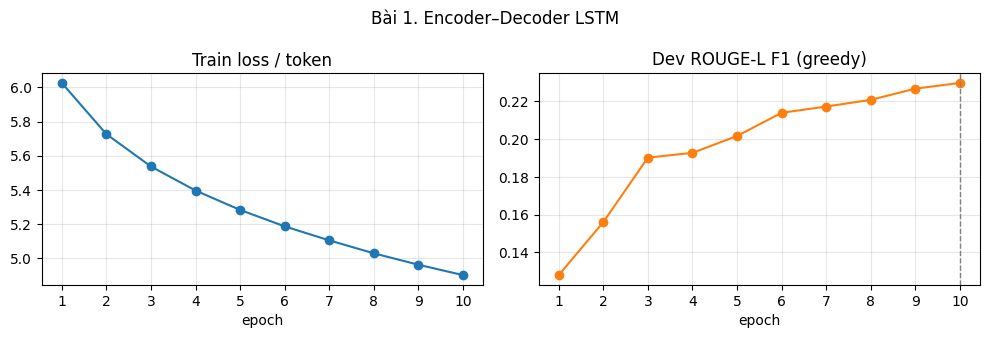

In [23]:
plot_history('none', 'Bài 1. Encoder–Decoder LSTM')

### Nhận xét Bài 1

Loss train giảm đều từ 6.03 xuống 4.90 sau 10 epoch, ROUGE-L dev tăng từ 0.128 lên 0.230. Epoch 10 vẫn là epoch tốt nhất và đường cong chưa phẳng, nên mô hình chưa hội tụ khi dừng ở giới hạn 10 epoch của đề. Cả câu nguồn phải đi qua một cặp trạng thái (h, c) cố định trước khi decoder bắt đầu sinh.

## 7. Bài 2. Bahdanau attention

Giữ nguyên dữ liệu, từ điển, seed và cấu hình như Bài 1, chỉ thay decoder bằng bản có Bahdanau attention.

In [24]:
seed_all()
model = make_seq2seq('bahdanau')
print('số tham số:', f'{n_params(model):,}')
histories['bahdanau'], best_epochs['bahdanau'] = fit(model, 'bahdanau')
models['bahdanau'] = model

số tham số: 8,025,763
bahdanau epoch  1: loss 6.0413 | dev ROUGE-L 0.1413 | dev NLL 5.9062 | BLEU 0.17 | 120s
bahdanau epoch  2: loss 5.6456 | dev ROUGE-L 0.1985 | dev NLL 5.4816 | BLEU 1.17 | 111s
bahdanau epoch  3: loss 5.3636 | dev ROUGE-L 0.2175 | dev NLL 5.2202 | BLEU 1.64 | 114s
bahdanau epoch  4: loss 5.1682 | dev ROUGE-L 0.2445 | dev NLL 5.0422 | BLEU 2.38 | 113s
bahdanau epoch  5: loss 4.9980 | dev ROUGE-L 0.2525 | dev NLL 4.8937 | BLEU 2.68 | 115s
bahdanau epoch  6: loss 4.8640 | dev ROUGE-L 0.2721 | dev NLL 4.7743 | BLEU 3.48 | 103s
bahdanau epoch  7: loss 4.7457 | dev ROUGE-L 0.2755 | dev NLL 4.6804 | BLEU 3.66 | 104s
bahdanau epoch  8: loss 4.6416 | dev ROUGE-L 0.2856 | dev NLL 4.6027 | BLEU 3.96 | 103s
bahdanau epoch  9: loss 4.5577 | dev ROUGE-L 0.2948 | dev NLL 4.5434 | BLEU 4.48 | 103s
bahdanau epoch 10: loss 4.4777 | dev ROUGE-L 0.2975 | dev NLL 4.4868 | BLEU 4.56 | 99s
epoch tốt nhất: 10


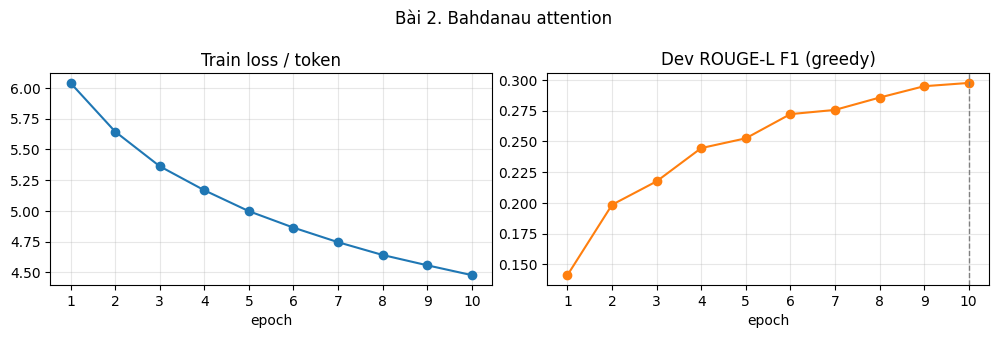

In [25]:
plot_history('bahdanau', 'Bài 2. Bahdanau attention')

### Nhận xét Bài 2

Loss train giảm từ 6.04 xuống 4.48 và thấp hơn Bài 1 ở mọi epoch từ epoch 2. ROUGE-L dev tăng từ 0.141 lên 0.2975, epoch tốt nhất vẫn là epoch 10 nên mô hình cũng chưa hội tụ. Mỗi epoch mất khoảng 109 giây, so với 73 giây ở Bài 1, vì attention được tính trên toàn bộ câu nguồn ở từng bước giải mã.

## 8. Bài 3. Luong attention

Giữ nguyên cấu hình chung, decoder dùng Luong global attention với điểm general và input feeding.

In [26]:
seed_all()
model = make_seq2seq('luong')
print('số tham số:', f'{n_params(model):,}')
histories['luong'], best_epochs['luong'] = fit(model, 'luong')
models['luong'] = model

số tham số: 7,959,971
luong epoch  1: loss 6.0734 | dev ROUGE-L 0.1301 | dev NLL 5.9704 | BLEU 0.11 | 91s
luong epoch  2: loss 5.7382 | dev ROUGE-L 0.1692 | dev NLL 5.6299 | BLEU 0.81 | 90s
luong epoch  3: loss 5.5026 | dev ROUGE-L 0.1936 | dev NLL 5.3820 | BLEU 1.20 | 90s
luong epoch  4: loss 5.2998 | dev ROUGE-L 0.2208 | dev NLL 5.1708 | BLEU 1.77 | 90s
luong epoch  5: loss 5.1162 | dev ROUGE-L 0.2355 | dev NLL 4.9919 | BLEU 2.26 | 90s
luong epoch  6: loss 4.9604 | dev ROUGE-L 0.2503 | dev NLL 4.8394 | BLEU 2.88 | 91s
luong epoch  7: loss 4.8296 | dev ROUGE-L 0.2664 | dev NLL 4.7293 | BLEU 3.46 | 91s
luong epoch  8: loss 4.7166 | dev ROUGE-L 0.2775 | dev NLL 4.6340 | BLEU 3.91 | 90s
luong epoch  9: loss 4.6231 | dev ROUGE-L 0.2865 | dev NLL 4.5666 | BLEU 4.20 | 92s
luong epoch 10: loss 4.5282 | dev ROUGE-L 0.2905 | dev NLL 4.4988 | BLEU 4.49 | 91s
epoch tốt nhất: 10


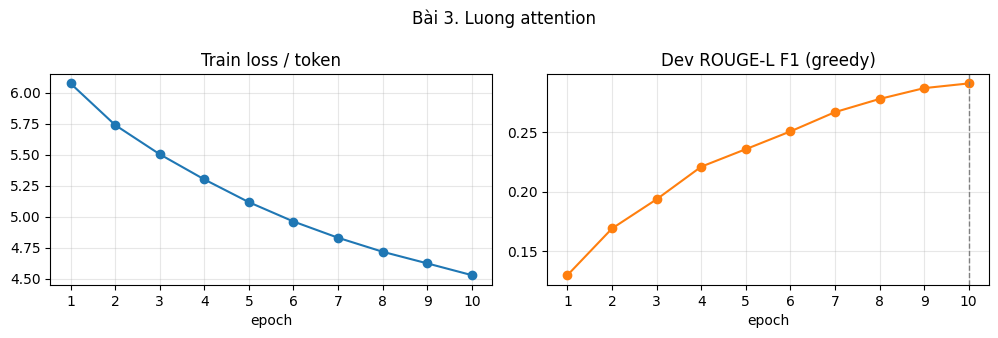

In [27]:
plot_history('luong', 'Bài 3. Luong attention')

### Nhận xét Bài 3

Loss train giảm từ 6.07 xuống 4.53, nằm giữa Bài 1 và Bài 2 từ epoch 3 trở đi. ROUGE-L dev tăng từ 0.130 lên 0.2905, epoch tốt nhất là epoch 10. Mỗi epoch mất khoảng 91 giây.

## 9. Đánh giá trên test

Ba checkpoint đã chốt bằng dev ở trên. Test chỉ chạy một lần ở đây và không dùng để chỉnh gì thêm.

In [28]:
test_out, rows = {}, []
for name, model in models.items():
    metrics, test_out[name] = evaluate(model, filtered['test'], keep=True)
    metrics.pop('dev_nll')
    rows.append(dict(model=name, **metrics))
test_table = pd.DataFrame(rows)
test_table.to_csv(ART/'test_metrics.csv', index=False)
test_table.round(4)

,model,rougeL_f1,rougeL_p,rougeL_r,bleu,empty
0,none,0.2346,0.2608,0.2161,2.6148,0.0
1,bahdanau,0.3138,0.3403,0.2957,5.8295,0.0
2,luong,0.3054,0.3315,0.2873,5.5179,0.0


### Nhận xét kết quả test

ROUGE-L test là 0.2346 (không attention), 0.3138 (Bahdanau) và 0.3054 (Luong), cùng thứ tự với dev. Điểm test cao hơn dev khoảng 0.005 đến 0.016 ở cả ba mô hình. Test không tham gia chọn checkpoint, nên chênh lệch này chỉ phản ánh khác biệt giữa hai tập. Precision cao hơn recall ở cả ba mô hình, tức câu sinh ngắn hơn câu tham chiếu.

## 10. Câu dịch mẫu

Mỗi mô hình lấy 3 câu test có câu tham chiếu dài 8–25 từ: câu có ROUGE-L cao nhất, câu ở trung vị và câu thấp nhất.

In [29]:
test_by_id = {r['id']: r for r in filtered['test']}

def per_sentence(name):
    out = test_out[name]
    df = pd.DataFrame(dict(id=out['ids'], hyp=out['hyps'], ref=out['refs']))
    df['rougeL'] = [rouge.score(r, h)['rougeL'].fmeasure for h, r in zip(df.hyp, df.ref)]
    df['src'] = [' '.join(test_by_id[i]['src']) for i in df.id]
    return df

def show_samples(name):
    df = per_sentence(name)
    df = df[df.ref.str.split().str.len().between(8, 25)].sort_values(['rougeL', 'id'], ascending=[False, True])
    picks = [('cao nhất', df.iloc[0]), ('trung vị', df.iloc[len(df) // 2]), ('thấp nhất', df.iloc[-1])]
    for label, r in picks:
        print(f"[{label}] id {r.id} | ROUGE-L {r.rougeL:.3f}")
        print('  EN :', r.src)
        print('  REF:', r.ref)
        print('  OUT:', r.hyp)
        print()

for name in models:
    print('=' * 20, name, '=' * 20)
    show_samples(name)

==================== none ====================
[cao nhất] id 851 | ROUGE-L 0.778
  EN : it was n't what i wanted to do .
  REF: đó không phải là điều mà tôi muốn làm .
  OUT: đó là điều tôi tôi muốn làm .

[trung vị] id 1516 | ROUGE-L 0.250
  EN : i 'm primarily a moral philosopher .
  REF: tôi chủ yếu nghiên cứu về đạo đức .
  OUT: tôi là một một một . .

[thấp nhất] id 1221 | ROUGE-L 0.000
  EN : the construction began in 1837 .
  REF: việc xây dựng bắt đầu năm 1873 ,
  OUT: những người của của đã . .

==================== bahdanau ====================
[cao nhất] id 907 | ROUGE-L 0.900
  EN : ( laughter ) ( applause ) thank you .
  REF: ( cười ) ( vỗ tay ) cám ơn .
  OUT: ( cười ) ( vỗ tay ) cảm ơn .

[trung vị] id 1868 | ROUGE-L 0.333
  EN : but as in so many other industries , computing has changed everything .
  REF: nhưng cũng như trong những ngành công nghiệp khác , máy tính đã làm thay đổi mọi thứ .
  OUT: nhưng khi nhiều nhiều khác khác , , , , thay đổi thay đổi thay đổi .

[t

### Nhận xét câu dịch mẫu

Câu dịch đúng là câu ngắn, từ phổ biến, cấu trúc gần với tiếng Anh. "and now i do that ." (Luong, ROUGE-L 0.875) thiếu "bây" và thừa "đã" so với tham chiếu. "( laughter ) ( applause ) thank you ." (Bahdanau, 0.9) chỉ khác "cảm ơn" và "cám ơn", là khác biệt chính tả chứ không phải sai nghĩa. Câu 851 của Bài 1 bỏ mất phần phủ định ("không phải") nên nghĩa ngược với câu nguồn, và lặp "tôi".

Câu dài dịch sai nhiều. Bản dịch lặp từ ("một một một một", "của của của của", "thay đổi thay đổi thay đổi") và bỏ phần lớn nội dung. Câu 250 là câu thấp nhất của cả Bahdanau và Luong (ROUGE-L 0): bản dịch đầy `<unk>` và không liên quan tới câu nguồn. Câu 1221 của Bài 1 có nguồn ghi 1837 nhưng tham chiếu ghi 1873, là lỗi của dữ liệu.

Ba câu mỗi mô hình được chọn theo ROUGE-L trên test (cao nhất, trung vị, thấp nhất) để minh họa, không dùng để chỉnh mô hình. Thống kê lặp token ở cuối phần 12.

## 11. Heatmap attention

Chọn 3 câu test có câu nguồn 6–12 từ, lấy 3 câu có ROUGE-L trung bình của hai mô hình attention cao nhất để heatmap dễ đọc. Dùng cùng 3 câu cho Bahdanau và Luong. Hàng là token sinh ra (đến `<eos>`), cột là token nguồn kể cả `<eos>`; token nguồn ngoài từ điển hiển thị là `<unk>` vì mô hình chỉ thấy như vậy.

id được chọn: [1776, 1105, 466]


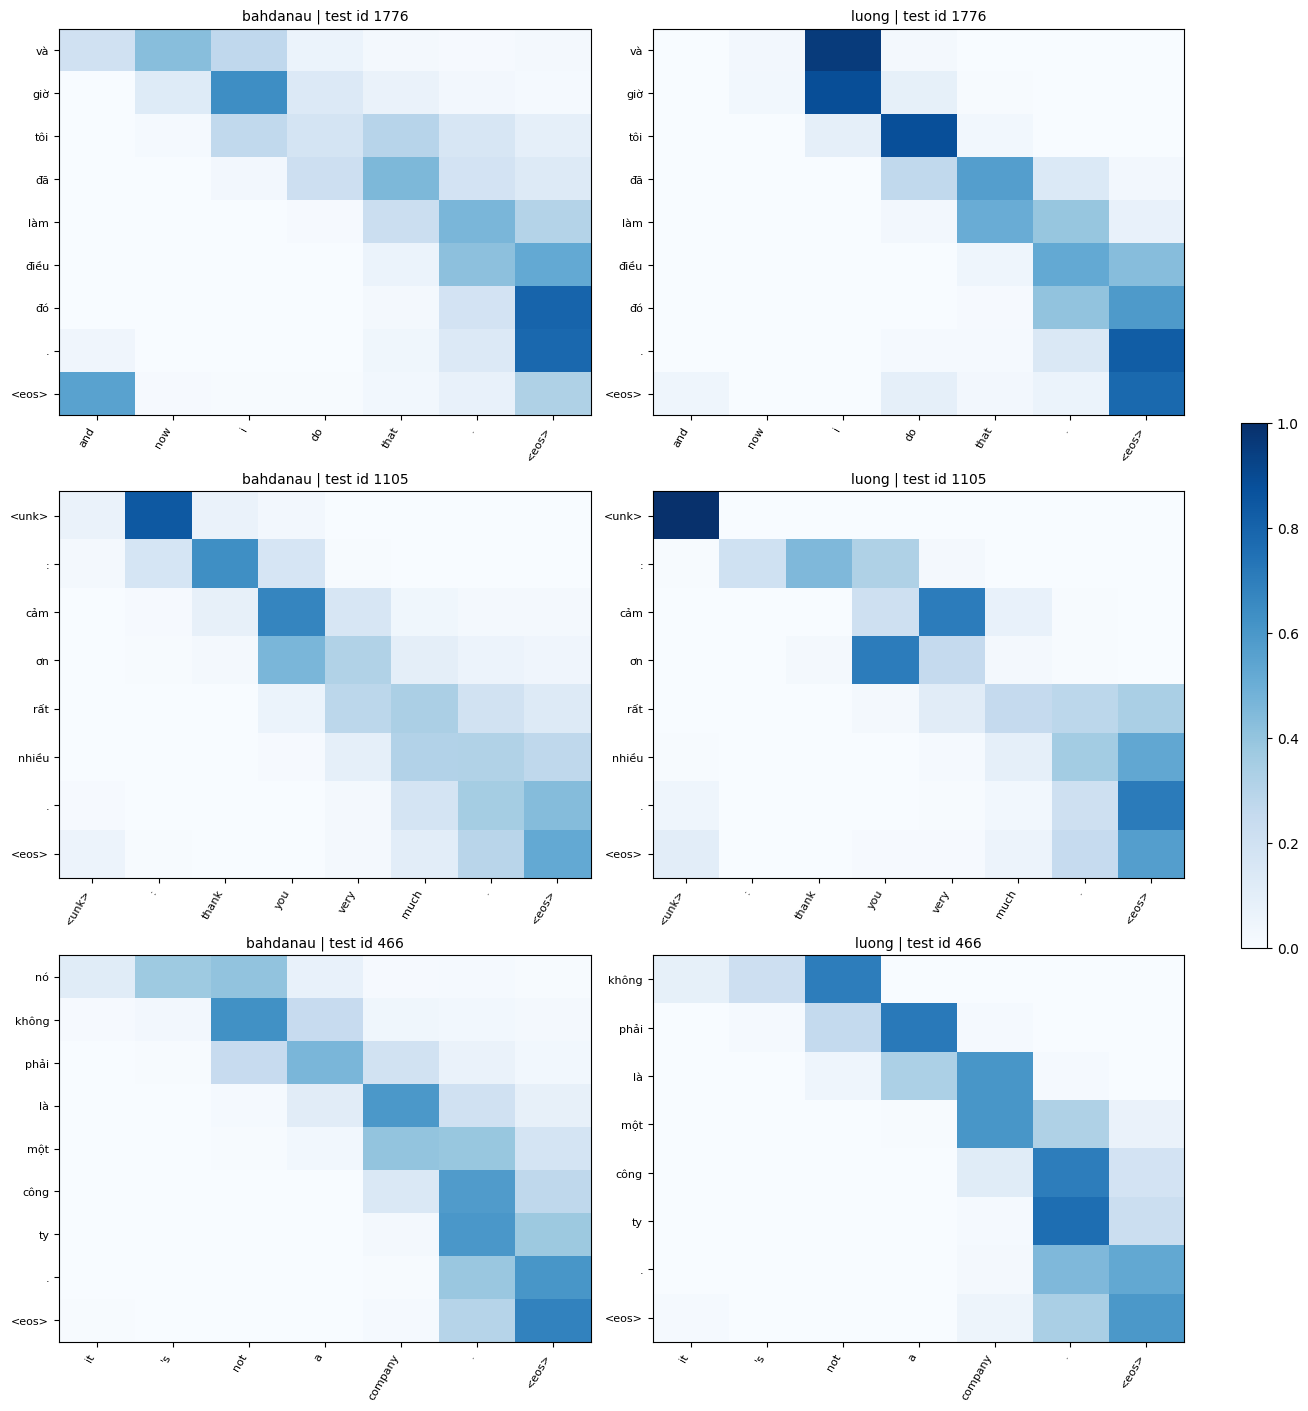

1776 | EN : and now i do that .
     | REF: và bây giờ tôi làm điều đó .
1105 | EN : dm : thank you very much .
     | REF: dm : cảm ơn rất nhiều .
466 | EN : it 's not a company .
     | REF: không phải là 1 công ty .


In [30]:
scores = pd.concat([per_sentence(n).set_index('id').rougeL.rename(n) for n in ['bahdanau', 'luong']], axis=1)
short = [i for i in scores.index if 6 <= len(test_by_id[i]['src']) <= 12]
heat_ids = scores.loc[short].mean(axis=1).sort_values(ascending=False, kind='stable').index[:3].tolist()
print('id được chọn:', heat_ids)

fig, axes = plt.subplots(3, 2, figsize=(13, 14), constrained_layout=True)
for row, sid in enumerate(heat_ids):
    one = collate([test_by_id[sid]])
    src = one['src'].to(device)
    x_labels = [src_itos[int(i)] for i in one['src'][0]]
    for col, name in enumerate(['bahdanau', 'luong']):
        ids, weights = generate(models[name], src, one['lengths'], cfg['max_words'] + 1)
        ids = ids[0].cpu().tolist()
        stop = ids.index(EOS) + 1 if EOS in ids else len(ids)
        matrix = weights[0, :stop].cpu().numpy()
        assert np.allclose(matrix.sum(-1), 1.0, atol=1e-4)
        ax = axes[row, col]
        image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
        ax.set_xticks(range(len(x_labels)), x_labels, rotation=60, ha='right', fontsize=8)
        ax.set_yticks(range(stop), [tgt_itos[i] for i in ids[:stop]], fontsize=8)
        ax.set_title(f'{name} | test id {sid}', fontsize=10)
fig.colorbar(image, ax=axes, shrink=0.4)
fig.savefig(ART/'attention_heatmaps.png', dpi=150)
plt.show()

for sid in heat_ids:
    print(sid, '| EN :', ' '.join(test_by_id[sid]['src']))
    print('     | REF:', ' '.join(test_by_id[sid]['tgt']))

In [34]:
# Token nguồn có trọng số attention lớn nhất ở từng bước giải mã (3 câu của heatmap)
peak = {'bahdanau': [], 'luong': []}
for sid in heat_ids:
    one = collate([test_by_id[sid]])
    src = one['src'].to(device)
    words = [src_itos[int(i)] for i in one['src'][0]]
    for name in peak:
        ids, weights = generate(models[name], src, one['lengths'], cfg['max_words'] + 1)
        ids = ids[0].cpu().tolist()
        stop = ids.index(EOS) + 1 if EOS in ids else len(ids)
        top = weights[0, :stop].max(-1)
        peak[name] += top.values.tolist()
        pairs = [f"{tgt_itos[ids[k]]}->{words[int(top.indices[k])]}({top.values[k]:.2f})" for k in range(stop)]
        print(sid, name, ' | '.join(pairs))
for name, values in peak.items():
    print(f'{name}: trọng số lớn nhất trung bình {np.mean(values):.3f} trên {len(values)} bước')

1776 bahdanau và->now(0.43) | giờ->i(0.64) | tôi->that(0.29) | đã->that(0.46) | làm->.(0.46) | điều-><eos>(0.52) | đó-><eos>(0.80) | .-><eos>(0.78) | <eos>->and(0.55)
1776 luong và->i(0.96) | giờ->i(0.88) | tôi->do(0.88) | đã->that(0.57) | làm->that(0.51) | điều->.(0.52) | đó-><eos>(0.59) | .-><eos>(0.83) | <eos>-><eos>(0.78)
1105 bahdanau <unk>->:(0.84) | :->thank(0.63) | cảm->you(0.67) | ơn->you(0.46) | rất->much(0.34) | nhiều->.(0.31) | .-><eos>(0.44) | <eos>-><eos>(0.52)
1105 luong <unk>-><unk>(1.00) | :->thank(0.45) | cảm->very(0.70) | ơn->you(0.70) | rất-><eos>(0.34) | nhiều-><eos>(0.53) | .-><eos>(0.71) | <eos>-><eos>(0.57)
466 bahdanau nó->not(0.41) | không->not(0.63) | phải->a(0.46) | là->company(0.60) | một->company(0.40) | công->.(0.58) | ty->.(0.60) | .-><eos>(0.61) | <eos>-><eos>(0.68)
466 luong không->not(0.70) | phải->a(0.72) | là->company(0.60) | một->company(0.61) | công->.(0.70) | ty->.(0.76) | .-><eos>(0.52) | <eos>-><eos>(0.60)
bahdanau: trọng số lớn nhất trung bình

### Nhận xét heatmap

Attention của cả hai mô hình có dạng gần đường chéo: token đầu câu đích nhìn vào phần đầu câu nguồn, token cuối nhìn vào cuối. Vị trí nhìn thường lệch về phía sau khoảng 1 đến 2 token so với từ tương ứng. Ở câu 1776, "và" và "giờ" của Luong cùng nhìn vào "i", "tôi" nhìn vào "do". Ở câu 1105, "cảm" nhìn vào "you" (Bahdanau) hoặc "very" (Luong) thay vì "thank". Một số chỗ đúng vị trí, ví dụ "không" nhìn vào "not" ở câu 466. Dấu chấm và `<eos>` gần như luôn nhìn vào `<eos>` của câu nguồn.

Luong tập trung hơn: trọng số lớn nhất trung bình 0.669, so với 0.543 của Bahdanau (bảng phía trên). Trên heatmap, Bahdanau trải trên 2 đến 3 token lân cận. Hàng `<eos>` của Bahdanau ở câu 1776 nhìn vào "and" (0.55) thay vì `<eos>`.

"dm" ở câu 1105 nằm ngoài từ điển nên token nguồn là `<unk>`, và cả hai mô hình sinh `<unk>` ở đầu câu đích. Trọng số attention là phân phối mềm, không phải căn chỉnh từ chính xác, và chỉ có 3 câu nên không đủ để khái quát.

## 12. Bảng tổng hợp

In [31]:
names = {'none': 'Bài 1. Không attention', 'bahdanau': 'Bài 2. Bahdanau', 'luong': 'Bài 3. Luong'}
summary = []
for name in models:
    h = pd.DataFrame(histories[name]).set_index('epoch')
    t = test_table.set_index('model').loc[name]
    summary.append({
        'Mô hình': names[name],
        'ROUGE-L dev': h.loc[best_epochs[name], 'rougeL_f1'],
        'ROUGE-L test': t.rougeL_f1,
        'Số tham số': n_params(models[name]),
        'Giây/epoch': h.seconds.mean(),
        'Epoch tốt nhất': best_epochs[name],
        'BLEU test': t.bleu,
    })
summary = pd.DataFrame(summary)
summary.to_csv(ART/'summary.csv', index=False)
summary.round(4)

,Mô hình,ROUGE-L dev,ROUGE-L test,Số tham số,Giây/epoch,Epoch tốt nhất,BLEU test
0,Bài 1. Không attention,0.2298,0.2346,7500963,72.8404,10,2.6148
1,Bài 2. Bahdanau,0.2975,0.3138,8025763,108.5286,10,5.8295
2,Bài 3. Luong,0.2905,0.3054,7959971,90.6830,10,5.5179


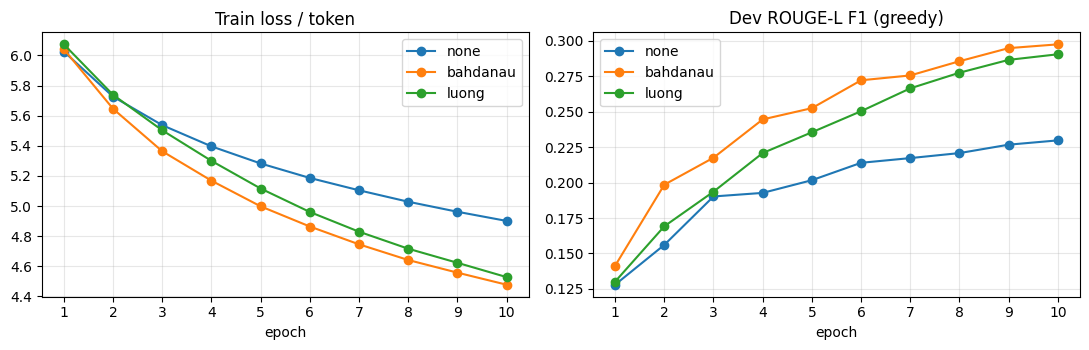

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name in models:
    h = pd.DataFrame(histories[name])
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=name)
    axes[1].plot(h.epoch, h.rougeL_f1, marker='o', label=name)
axes[0].set_title('Train loss / token')
axes[1].set_title('Dev ROUGE-L F1 (greedy)')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(ART/'curves_all.png', dpi=150)
plt.show()

In [35]:
# Phân tích thêm trên test: điểm theo độ dài câu nguồn, độ dài câu sinh, lặp token liền kề
def has_repeat(words):
    return any(a == b for a, b in zip(words, words[1:]))

rows = []
for name, o in test_out.items():
    for i, h, r in zip(o['ids'], o['hyps'], o['refs']):
        rows.append(dict(model=name, src_len=len(test_by_id[i]['src']), hyp_len=len(h.split()),
                         ref_len=len(r.split()), rouge=rouge.score(r, h)['rougeL'].fmeasure,
                         repeat=has_repeat(h.split())))
stats = pd.DataFrame(rows)
stats['nhóm'] = pd.cut(stats.src_len, [0, 10, 20, 30, 50], labels=['1-10', '11-20', '21-30', '31-50'])
print('Số câu test theo độ dài nguồn (từ):')
print(stats[stats.model == 'none']['nhóm'].value_counts().sort_index().to_string())
print('\nROUGE-L theo nhóm độ dài nguồn:')
print(stats.pivot_table(index='nhóm', columns='model', values='rouge', observed=True).round(4).to_string())
print('\nĐộ dài trung bình (từ):')
print(stats.groupby('model')[['hyp_len', 'ref_len']].mean().round(1).to_string())
print('\nTỉ lệ câu có hai token liền nhau giống nhau:')
print(stats.groupby('model').repeat.mean().round(3).to_string())
print('tham chiếu', round(np.mean([has_repeat(r.split()) for r in test_out['none']['refs']]), 3))

Số câu test theo độ dài nguồn (từ):
nhóm
1-10     318
11-20    688
21-30    531
31-50    249

ROUGE-L theo nhóm độ dài nguồn:
model  bahdanau   luong    none
nhóm                           
1-10     0.4061  0.4055  0.3373
11-20    0.3224  0.3138  0.2418
21-30    0.2742  0.2643  0.1949
31-50    0.2566  0.2417  0.1683

Độ dài trung bình (từ):
          hyp_len  ref_len
model                     
bahdanau     21.8     24.7
luong        21.9     24.7
none         20.7     24.7

Tỉ lệ câu có hai token liền nhau giống nhau:
model
bahdanau    0.918
luong       0.917
none        0.924
tham chiếu 0.018


### So sánh ba mô hình và kết luận

Hai mô hình có attention cao hơn mô hình không attention khoảng 0.06 đến 0.08 ROUGE-L trên cả dev và test (test: 0.3138 và 0.3054 so với 0.2346). BLEU test tăng từ 2.61 lên 5.83 và 5.52. Bahdanau cao hơn Luong 0.007 trên dev và 0.008 trên test. Chênh lệch này nhỏ và chỉ có một lần chạy (một seed), nên chưa đủ để kết luận Bahdanau tốt hơn Luong. Với cấu hình của đề, Bahdanau có điểm cao nhất, đổi lại mỗi epoch chậm hơn (109 giây, so với 91 giây của Luong và 73 giây của không attention).

Điểm ROUGE-L giảm khi câu nguồn dài ở cả ba mô hình (Bahdanau: 0.406 ở nhóm 1 đến 10 từ, 0.257 ở nhóm 31 đến 50 từ). Khoảng cách giữa Bahdanau và không attention là 0.07 đến 0.09 ở mọi nhóm và lớn nhất ở nhóm dài nhất (0.088). Số liệu phù hợp với cách giải thích rằng attention cho decoder lấy thông tin trực tiếp từ từng token nguồn thay vì chỉ dựa vào một vector cố định, nhưng chưa chứng minh được nguyên nhân.

Điểm tuyệt đối còn thấp. Khoảng 92% câu sinh có hai token liền nhau giống nhau (tham chiếu: 1.8%), câu sinh ngắn hơn tham chiếu (khoảng 21 so với 24.7 từ), và từ hiếm thành `<unk>`. Nguyên nhân có thể gồm dữ liệu ít (18607 cặp), chưa hội tụ sau 10 epoch, giải mã greedy và tách từ theo khoảng trắng. Các yếu tố này chưa được tách riêng để kiểm chứng.

## 13. Lưu metadata và kiểm tra checkpoint

Lưu cấu hình, từ điển, id các câu đã dùng và history. Sau đó nạp lại từng checkpoint từ file `.pt` vào mô hình mới, so logits với mô hình trong bộ nhớ và chấm lại dev để chắc file lưu đúng epoch tốt nhất.

In [33]:
metadata = dict(config=cfg, seed=42, device=str(device), torch=torch.__version__,
                normalization='bỏ BOM, NFC, viết thường, tách theo khoảng trắng',
                files=DATA_FILES, src_vocab=src_vocab, tgt_vocab=tgt_vocab,
                train_ids=[r['id'] for r in train_rows], dev_ids=[r['id'] for r in dev_rows],
                histories=histories, best_epochs=best_epochs, heatmap_test_ids=heat_ids)
(ART/'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=1), encoding='utf-8')

check = next(iter(loader(dev_rows)))
args = (check['src'].to(device), check['lengths'], check['tgt'].to(device))
for name in models:
    restored = make_seq2seq(name)
    restored.load_state_dict(torch.load(ART/f'{name}.pt', map_location=device, weights_only=True))
    restored.eval()
    with torch.no_grad():
        torch.testing.assert_close(restored(*args, teacher_ratio=1.0), models[name](*args, teacher_ratio=1.0))
    again = evaluate(restored, dev_rows)['rougeL_f1']
    saved = histories[name][best_epochs[name] - 1]['rougeL_f1']
    print(f'{name:9} dev ROUGE-L lúc train {saved:.6f} | nạp lại {again:.6f} | lệch {abs(again - saved):.2e}')

none      dev ROUGE-L lúc train 0.229751 | nạp lại 0.229751 | lệch 0.00e+00
bahdanau  dev ROUGE-L lúc train 0.297466 | nạp lại 0.297466 | lệch 0.00e+00
luong     dev ROUGE-L lúc train 0.290467 | nạp lại 0.290467 | lệch 0.00e+00
